In [ ]:
#Requirements
openai-whisper
torch
librosa>=0.10.2,<1.0
numpy
pandas
plotly



In [1]:
!pip install -q faster-whisper sounddevice

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 52.6 MB/s eta 0:00:00


In [2]:
!pip install -q librosa matplotlib
!ffmpeg -y -i my_speech.webm -ac 1 -ar 22050 speech.wav -loglevel error

[in#0 @ 0x557e5cfe1c40] Error opening input: No such file or directory
Error opening input file my_speech.webm.
Error opening input files: No such file or directory


In [ ]:
!pip install -U av

In [3]:
!pip uninstall -y av faster-whisper
!pip install "av==14.4.0" "faster-whisper==1.1.1"

Found existing installation: av 19.0.1
Uninstalling av-19.0.1:
  Successfully uninstalled av-19.0.1
Found existing installation: faster-whisper 1.2.1
Uninstalling faster-whisper-1.2.1:
  Successfully uninstalled faster-whisper-1.2.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 108.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [4]:
!pip install -q -U openai-whisper
!apt-get -qq update
!apt-get -qq install -y ffmpeg

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 47.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [6]:
from IPython.display import display, Javascript
from google.colab import output
from base64 import b64decode

duration_seconds = 0

def save_recording(data_url, duration):
    global duration_seconds

    encoded = data_url.split(",", 1)[1]
    with open("my_speech.webm", "wb") as f:
        f.write(b64decode(encoded))

    duration_seconds = float(duration)
    print(f"Recording saved! Duration: {duration_seconds:.2f} seconds")

output.register_callback("notebook.save_recording", save_recording)

display(Javascript("""
(() => {
  const box = document.createElement('div');
  box.style = 'padding:16px;border:1px solid #aaa;border-radius:12px';

  const start = document.createElement('button');
  start.textContent = 'Start Recording';
  start.style = 'padding:10px;background:#16a34a;color:white;border:0;border-radius:6px;margin-right:8px';

  const stop = document.createElement('button');
  stop.textContent = 'Stop Recording';
  stop.disabled = true;
  stop.style = 'padding:10px;background:#dc2626;color:white;border:0;border-radius:6px';

  const status = document.createElement('p');
  status.textContent = 'Ready to record.';

  box.append(start, stop, status);
  document.body.appendChild(box);

  let recorder, stream, chunks = [], startedAt;

  start.onclick = async () => {
    try {
      stream = await navigator.mediaDevices.getUserMedia({audio:true});
      recorder = new MediaRecorder(stream);
      chunks = [];

      recorder.ondataavailable = e => {
        if (e.data.size) chunks.push(e.data);
      };

      recorder.onstop = () => {
        const blob = new Blob(chunks, {type:recorder.mimeType});
        const reader = new FileReader();

        reader.onloadend = async () => {
          try {
            await google.colab.kernel.invokeFunction(
              'notebook.save_recording',
              [reader.result, (Date.now()-startedAt)/1000],
              {}
            );
            status.textContent = 'Recording saved successfully!';
          } catch (err) {
            status.textContent = 'Save error: ' + err.message;
          } finally {
            stream.getTracks().forEach(t => t.stop());
            start.disabled = false;
            stop.disabled = true;
          }
        };

        reader.readAsDataURL(blob);
      };

      recorder.start();
      startedAt = Date.now();
      start.disabled = true;
      stop.disabled = false;
      status.textContent = 'Recording... Speak now!';
    } catch (err) {
      status.textContent = 'Microphone error: ' + err.message;
    }
  };

  stop.onclick = () => {
    if (recorder && recorder.state === 'recording') {
      recorder.stop();
      stop.disabled = true;
      status.textContent = 'Saving recording...';
    }
  };
})();
"""))

<IPython.core.display.Javascript object>

Recording saved! Duration: 17.16 seconds


In [8]:

# ============================================================
# AI PUBLIC SPEAKING ANALYZER - ALL-IN-ONE CELL
# Transcript + Filler Words + Speaking Stats + Word Timestamps
# + Sentence Timestamps + Long Pause Detection
# ============================================================

import whisper
import torch
import re
from collections import Counter

# -------------------- SETTINGS --------------------
AUDIO_FILE = "my_speech.webm"
LANGUAGE = "en"       # Examples: "en", "hi", "mr", "ta", "te", "kn"
MODEL_NAME = "small"
PAUSE_THRESHOLD = 2.0  # Seconds

# -------------------- LOAD MODEL --------------------
print("Loading Whisper model...")
model = whisper.load_model(MODEL_NAME)

# -------------------- TRANSCRIBE ONCE --------------------
verbatim_prompt = (
    "Transcribe this speech verbatim. Preserve hesitations, filler words, "
    "repetitions, incomplete phrases, and informal speech. Do not clean up "
    "or summarize. Listen for um, umm, uh, uhh, erm, hmm, like, you know, "
    "and I mean."
)

print("Transcribing audio and finding word timestamps...")

result = model.transcribe(
    AUDIO_FILE,
    language=LANGUAGE,
    task="transcribe",
    word_timestamps=True,
    fp16=torch.cuda.is_available(),
    initial_prompt=verbatim_prompt,
    condition_on_previous_text=False,
    temperature=0
)

transcript = result["text"].strip()

# -------------------- TRANSCRIPT --------------------
print("\n" + "=" * 55)
print("VERBATIM TRANSCRIPT")
print("=" * 55)
print(transcript)

# -------------------- WORD DATA --------------------
word_data = []

for segment in result["segments"]:
    for word in segment.get("words", []):
        word_data.append({
            "word": word["word"].strip(),
            "start": float(word["start"]),
            "end": float(word["end"])
        })

# -------------------- SENTENCE TIMESTAMP DATA --------------------
# Group word timestamps into sentences using punctuation.
# Sentence boundaries depend on Whisper's punctuation output.

sentence_data = []
current_sentence_words = []

def create_sentence_record(words):
    """Create one sentence record from its word timestamps."""

    sentence_text = " ".join(
        item["word"] for item in words
    ).strip()

    # Fix spaces before punctuation.
    sentence_text = re.sub(
        r"\s+([,.;:!?])", r"\1", sentence_text
    )

    return {
        "sentence": sentence_text,
        "start": words[0]["start"],
        "end": words[-1]["end"],
        "duration": words[-1]["end"] - words[0]["start"]
    }


for item in word_data:
    current_sentence_words.append(item)
    token = item["word"].strip()

    # A sentence ends when a word ends with ., !, ?, or …
    # Allow closing quotation marks and brackets after punctuation.
    sentence_ended = bool(
        re.search(r"""[.!?…]+["'”’)\]}]*$""", token)
    )

    if sentence_ended:
        sentence_data.append(
            create_sentence_record(current_sentence_words)
        )
        current_sentence_words = []

# Keep any final sentence that has no ending punctuation.
if current_sentence_words:
    sentence_data.append(
        create_sentence_record(current_sentence_words)
    )

# -------------------- FILLER WORD ANALYSIS --------------------
text = transcript.lower()

filler_patterns = {
    "um": r"\bum+\b",
    "uh": r"\buh+\b",
    "erm": r"\berm+\b",
    "hmm": r"\bhm+\b",
    "you know": r"\byou\s+know\b",
    "I mean": r"\bi\s+mean\b",
    "basically": r"\bbasically\b",
    "actually": r"\bactually\b",
    "literally": r"\bliterally\b",
}

filler_counts = {
    name: len(re.findall(pattern, text))
    for name, pattern in filler_patterns.items()
}

# "Like" is a candidate because it can also be a normal word.
like_candidates = len(re.findall(r"\blike\b", text))

total_fillers = sum(filler_counts.values())
total_words = len(re.findall(r"\b[\w']+\b", text))

filler_percentage = (
    total_fillers / total_words * 100 if total_words else 0
)

# -------------------- SPEAKING STATISTICS --------------------
# Prefer the actual recording duration from your recording cell.
# If duration_seconds is unavailable, use the last word timestamp.
try:
    duration = float(duration_seconds)
except (NameError, TypeError, ValueError):
    duration = word_data[-1]["end"] if word_data else 0.0

duration_minutes = duration / 60
wpm = total_words / duration_minutes if duration_minutes > 0 else 0

sentences = [
    s for s in re.split(r'[.!?]+', transcript.strip()) if s.strip()
]
sentence_count = len(sentences)

average_sentence_length = (
    total_words / sentence_count if sentence_count else 0
)

# -------------------- SENTENCE-LEVEL TIMESTAMPS --------------------
print("\n" + "=" * 65)
print("SENTENCE-LEVEL TIMESTAMPS")
print("=" * 65)

if sentence_data:
    for number, sentence in enumerate(sentence_data, start=1):
        print(
            f'{sentence["start"]:7.2f}s - '
            f'{sentence["end"]:7.2f}s  '
            f'{sentence["sentence"]}'
        )
else:
    print("No sentence timestamps available.")

print(f"\nTotal timestamped sentences: {len(sentence_data)}")

# -------------------- LONG PAUSE DETECTION --------------------
pauses = []

for i in range(1, len(word_data)):
    previous_word = word_data[i - 1]
    current_word = word_data[i]

    pause_duration = current_word["start"] - previous_word["end"]

    if pause_duration >= PAUSE_THRESHOLD:
        pauses.append({
            "after_word": previous_word["word"],
            "before_word": current_word["word"],
            "pause_start": previous_word["end"],
            "pause_end": current_word["start"],
            "duration": pause_duration
        })

# -------------------- FINAL REPORT --------------------
print("\n" + "=" * 55)
print("SPEAKING REPORT")
print("=" * 55)

print(f"Duration: {duration:.2f} seconds")
print(f"Total transcript words: {total_words}")
print(f"Speaking speed: {wpm:.2f} words per minute")
print(f"Sentence count: {sentence_count}")
print(f"Average sentence length: {average_sentence_length:.2f} words")

print("\nFILLER WORD BREAKDOWN")
for word, count in filler_counts.items():
    print(f"{word}: {count}")

print(f"Total detected fillers: {total_fillers}")
print(f"'Like' occurrences to review: {like_candidates}")
print(f"Filler percentage: {filler_percentage:.2f}%")

print("\nLONG PAUSES (>= {:.1f} seconds)".format(PAUSE_THRESHOLD))

if pauses:
    for number, pause in enumerate(pauses, start=1):
        print(f"\nPause #{number}")
        print(f'After word: {pause["after_word"]}')
        print(f'Before word: {pause["before_word"]}')
        print(f'Start: {pause["pause_start"]:.2f} seconds')
        print(f'End: {pause["pause_end"]:.2f} seconds')
        print(f'Duration: {pause["duration"]:.2f} seconds')
else:
    print("No long pauses detected.")

print(f"\nTotal long pauses: {len(pauses)}")
print(
    "Total long-pause time: "
    f'{sum(p["duration"] for p in pauses):.2f} seconds'
)

print("\nAnalysis complete!")

Loading Whisper model...
Transcribing audio and finding word timestamps...

VERBATIM TRANSCRIPT
Hey guys, welcome back. Mmm, good night. Take care. Sweet dreams. On the occasion of Independence Day, we'll celebrate Ganesh Chathurthi. Thank you for coming.

SENTENCE-LEVEL TIMESTAMPS
   0.00s -    2.66s  Hey guys, welcome back.
   3.46s -    5.72s  Mmm, good night.
   6.20s -    6.48s  Take care.
   6.60s -    7.10s  Sweet dreams.
   8.50s -   12.52s  On the occasion of Independence Day, we'll celebrate Ganesh Chathurthi.
  13.38s -   14.56s  Thank you for coming.

Total timestamped sentences: 6

SPEAKING REPORT
Duration: 17.16 seconds
Total transcript words: 25
Speaking speed: 87.44 words per minute
Sentence count: 6
Average sentence length: 4.17 words

FILLER WORD BREAKDOWN
um: 0
uh: 0
erm: 0
hmm: 0
you know: 0
I mean: 0
basically: 0
actually: 0
literally: 0
Total detected fillers: 0
'Like' occurrences to review: 0
Filler percentage: 0.00%

LONG PAUSES (>= 2.0 seconds)
No long pauses d

In [9]:

import whisper
import librosa
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import re

# ==========================================================
# 1. LOAD AUDIO
# ==========================================================
audio_file = "/content/my_speech.webm"

y, sr = librosa.load(audio_file, sr=22050, mono=True)

# ==========================================================
# 2. GET WORD TIMESTAMPS USING WHISPER
#    Load the model only once per active Colab session.
# ==========================================================
if "pitch_whisper_model" not in globals():
    print("Loading Whisper model...")
    pitch_whisper_model = whisper.load_model("small")

result = pitch_whisper_model.transcribe(
    audio_file,
    language="en",
    word_timestamps=True,
    fp16=False,
    condition_on_previous_text=False
)

word_data = []

for segment in result["segments"]:
    for word in segment.get("words", []):
        word_data.append({
            "Word": word["word"].strip(),
            "Start (s)": float(word["start"]),
            "End (s)": float(word["end"])
        })

# ==========================================================
# 3. ESTIMATE PITCH
# ==========================================================
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=65,
    fmax=500,
    sr=sr,
    frame_length=2048,
    hop_length=256
)

times = librosa.times_like(f0, sr=sr, hop_length=256)

# ==========================================================
# 4. GROUP WORDS INTO SENTENCES
#    Each sentence gets its start and end timestamps.
# ==========================================================
sentence_data = []
current_sentence_words = []

for item in word_data:
    current_sentence_words.append(item)

    token = item["Word"]

    # Detect sentence-ending punctuation.
    sentence_ended = bool(
        re.search(r"[.!?…][\"'”’)\]]*$", token)
    )

    if sentence_ended:
        sentence_text = " ".join(
            word["Word"] for word in current_sentence_words
        )

        # Remove spaces before punctuation.
        sentence_text = re.sub(
            r"\s+([,.;:!?…])", r"\1", sentence_text
        )

        sentence_data.append({
            "Sentence": sentence_text,
            "Start (s)": current_sentence_words[0]["Start (s)"],
            "End (s)": current_sentence_words[-1]["End (s)"]
        })

        current_sentence_words = []

# Include remaining words if the final sentence has no punctuation.
if current_sentence_words:
    sentence_text = " ".join(
        word["Word"] for word in current_sentence_words
    )

    sentence_text = re.sub(
        r"\s+([,.;:!?…])", r"\1", sentence_text
    )

    sentence_data.append({
        "Sentence": sentence_text,
        "Start (s)": current_sentence_words[0]["Start (s)"],
        "End (s)": current_sentence_words[-1]["End (s)"]
    })

# ==========================================================
# 5. ASSIGN MEDIAN PITCH TO EACH SENTENCE
#    Pitch is calculated across voiced frames within the
#    sentence's start and end timestamps.
# ==========================================================
for item in sentence_data:
    start = item["Start (s)"]
    end = item["End (s)"]

    mask = (
        (times >= start) &
        (times < end) &
        np.isfinite(f0)
    )

    sentence_pitches = f0[mask]

    if len(sentence_pitches):
        item["Pitch (Hz)"] = round(
            float(np.median(sentence_pitches)), 1
        )
    else:
        item["Pitch (Hz)"] = np.nan

    item["Duration (s)"] = round(end - start, 2)
    item["Midpoint (s)"] = round((start + end) / 2, 2)

# Create sentence-level DataFrame.
df = pd.DataFrame(sentence_data)

# ==========================================================
# 6. DISPLAY TRANSCRIPT AND SENTENCE-LEVEL PITCH TABLE
# ==========================================================
print("TRANSCRIPT:")
print(result["text"].strip())

print("\nSENTENCE-LEVEL PITCH TABLE:")

if not df.empty:
    display(
        df[
            [
                "Sentence",
                "Start (s)",
                "End (s)",
                "Duration (s)",
                "Pitch (Hz)"
            ]
        ]
    )
else:
    print("No sentences were detected.")

# ==========================================================
# 7. INTERACTIVE SENTENCE-LEVEL PITCH GRAPH
#    Hover to see sentence, timestamps and median pitch.
# ==========================================================
if not df.empty:
    graph_df = df[np.isfinite(df["Pitch (Hz)"])].copy()

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=graph_df["Midpoint (s)"],
        y=graph_df["Pitch (Hz)"],
        mode="lines+markers",
        name="Sentence median pitch",
        customdata=graph_df[
            ["Sentence", "Start (s)", "End (s)", "Duration (s)"]
        ].to_numpy(),
        hovertemplate=(
            "<b>Sentence:</b> %{customdata[0]}<br>"
            "Start: %{customdata[1]:.2f} s<br>"
            "End: %{customdata[2]:.2f} s<br>"
            "Duration: %{customdata[3]:.2f} s<br>"
            "Median pitch: %{y:.1f} Hz"
            "<extra></extra>"
        )
    ))

    fig.update_layout(
        title="Sentence-Level Voice Pitch",
        xaxis_title="Sentence position in recording (seconds)",
        yaxis_title="Median pitch (Hz)",
        hovermode="closest",
        template="plotly_white",
        height=550
    )

    fig.show()
else:
    print("No sentence-level pitch data available for plotting.")

# ==========================================================
# 8. SAVE RESULTS
# ==========================================================
output_file = "/content/sentence_pitch_timestamps.csv"

df[
    [
        "Sentence",
        "Start (s)",
        "End (s)",
        "Duration (s)",
        "Pitch (Hz)"
    ]
].to_csv(output_file, index=False)

print("\nSaved sentence-level pitch table to:")
print(output_file)

print("\nAnalysis complete!")

/tmp/ipykernel_1868/3068393401.py:13: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_file, sr=22050, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Loading Whisper model...
TRANSCRIPT:
Hey guys welcome back. Good night. Take care sweet dreams. On the occasion of Independence Day we will celebrate Ganesh Chathurthi. Thank you for coming.

SENTENCE-LEVEL PITCH TABLE:


,Sentence,Start (s),End (s),Duration (s),Pitch (Hz)
0,Hey guys welcome back.,0.00,2.68,2.68,109.3
1,Good night.,3.96,5.72,1.76,106.2
2,Take care sweet dreams.,6.20,7.14,0.94,100.2
3,On the occasion of Independence Day we will ce...,8.50,12.54,4.04,103.2
4,Thank you for coming.,13.38,14.56,1.18,104.7



Saved sentence-level pitch table to:
/content/sentence_pitch_timestamps.csv

Analysis complete!


### **----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------**

/tmp/ipykernel_457/3958837247.py:6: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load("/content/my_speech.webm", sr=22050)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


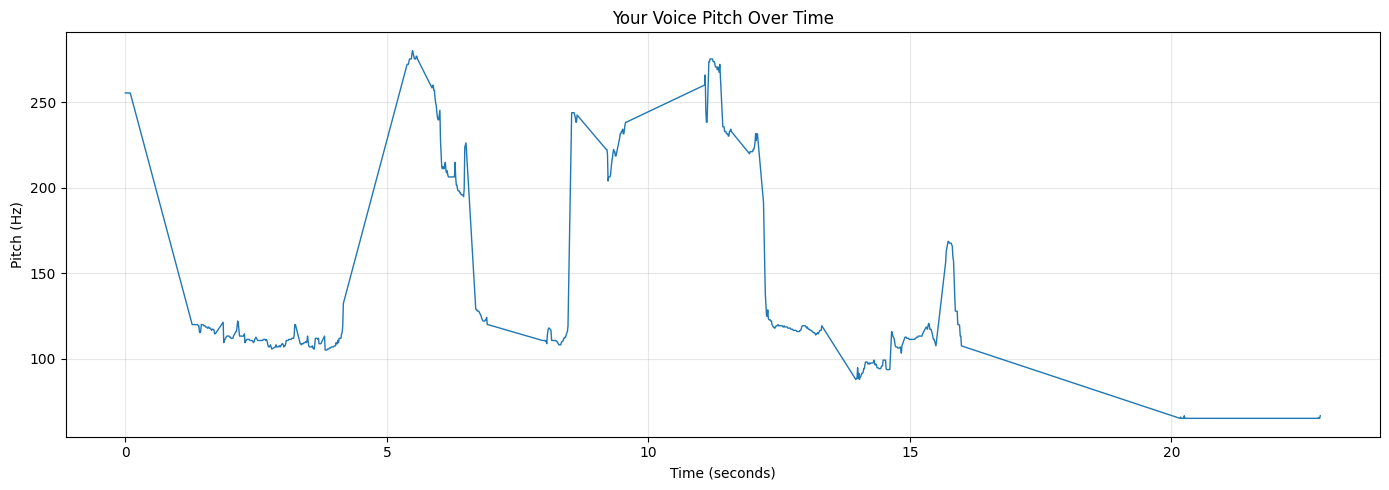

Mean pitch: 143.1 Hz
Minimum detected pitch: 65.0 Hz
Maximum detected pitch: 280.3 Hz
Pitch variation (standard deviation): 56.6 Hz


In [ ]:

# import librosa
# import numpy as np
# import matplotlib.pyplot as plt

# # Load recorded speech
# y, sr = librosa.load("/content/my_speech.webm", sr=22050)

# # Estimate fundamental frequency (F0)
# f0, voiced_flag, voiced_probs = librosa.pyin(
#     y,
#     fmin=65,
#     fmax=500,
#     sr=sr,
#     frame_length=2048,
#     hop_length=256
# )

# times = librosa.times_like(f0, sr=sr, hop_length=256)

# # Ignore frames where pitch could not be reliably estimated
# valid = np.isfinite(f0)

# plt.figure(figsize=(14, 5))
# plt.plot(times[valid], f0[valid], linewidth=1)
# plt.xlabel("Time (seconds)")
# plt.ylabel("Pitch (Hz)")
# plt.title("Your Voice Pitch Over Time")
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

# if valid.any():
#     print(f"Mean pitch: {np.mean(f0[valid]):.1f} Hz")
#     print(f"Minimum detected pitch: {np.min(f0[valid]):.1f} Hz")
#     print(f"Maximum detected pitch: {np.max(f0[valid]):.1f} Hz")
#     print(f"Pitch variation (standard deviation): {np.std(f0[valid]):.1f} Hz")
# else:
#     print("No reliable pitch detected. Try a clearer recording.")

In [ ]:

# import whisper
# import torch

# # Use "small" for better accuracy than "base".
# # If your Colab GPU has enough memory, you can try "medium".
# model = whisper.load_model("small")

# verbatim_prompt = (
#     "Transcribe this speech verbatim. Preserve hesitations, filler words, "
#     "repetitions, incomplete phrases, and informal speech. Do not clean up "
#     "or summarize what the speaker says. Listen carefully for um, umm, "
#     "uh, uhh, erm, hmm, like, you know, and I mean."
# )

# result = model.transcribe(
#     "my_speech.webm",
#     language="en",
#     fp16=torch.cuda.is_available(),
#     initial_prompt=verbatim_prompt,
#     condition_on_previous_text=False,
#     temperature=0
# )

# transcript = result["text"].strip()

# print("========== VERBATIM TRANSCRIPT ==========")
# print(transcript)
# print("========== VERBATIM TRANSCRIPT ==========")

# import re
# from collections import Counter

# text = transcript.lower()

# filler_patterns = {
#     "um": r"\bum+\b",
#     "uh": r"\buh+\b",
#     "erm": r"\berm+\b",
#     "hmm": r"\bhm+\b",
#     "you know": r"\byou\s+know\b",
#     "I mean": r"\bi\s+mean\b",
#     "basically": r"\bbasically\b",
#     "actually": r"\bactually\b",
#     "literally": r"\bliterally\b",
# }

# filler_counts = {
#     name: len(re.findall(pattern, text))
#     for name, pattern in filler_patterns.items()
# }

# # "Like" needs context, so count it separately as a candidate.
# like_candidates = len(re.findall(r"\blike\b", text))

# total_fillers = sum(filler_counts.values())
# total_words = len(re.findall(r"\b[\w']+\b", text))

# print("Filler word breakdown:")
# for word, count in filler_counts.items():
#     print(f"{word}: {count}")

# print(f"\nTotal detected fillers: {total_fillers}")
# print(f"'Like' occurrences to review: {like_candidates}")
# print(f"Total transcript words: {total_words}")
# print(
#     "Filler percentage:",
#     round(total_fillers / total_words * 100, 2) if total_words else 0,
#     "%"
# )
# print("\n========== SPEAKING REPORT ==========")
# print(f"Duration: {duration_seconds:.2f} seconds")
# print(f"Total words: {total_words}")
# print(f"Speaking speed: {wpm:.2f} words per minute")
# print(f"Filler word count: {total_fillers}")
# print(f"Filler percentage: {filler_percentage:.2f}%")
# print(f"Sentence count: {len(sentences)}")
# print(f"Average sentence length: {average_sentence_length:.2f} words")
# # print("Filler breakdown:", dict(filler_counts))
# print("=====================================")

========== VERBATIM TRANSCRIPT ==========
Extract all the words. Hi guys. Then what is next? Next is nothing. Extract it, what do you want? More shit, that is it. If I'm on video. Hmm.
========== VERBATIM TRANSCRIPT ==========
Filler word breakdown:
um: 0
uh: 0
erm: 0
hmm: 1
you know: 0
I mean: 0
basically: 0
actually: 0
literally: 0

Total detected fillers: 1
'Like' occurrences to review: 0
Total transcript words: 29
Filler percentage: 3.45 %

========== SPEAKING REPORT ==========
Duration: 20.44 seconds
Total words: 29
Speaking speed: 43.52 words per minute
Filler word count: 1
Filler percentage: 0.00%
Sentence count: 1
Average sentence length: 16.00 words


In [ ]:

# import whisper

# model = whisper.load_model("base")

# result = model.transcribe(
#     "my_speech.webm",
#     language="en",
#     fp16=False
# )

# transcript = result["text"].strip()

# print("========== YOUR TRANSCRIPT ==========")
# print(transcript)

========== YOUR TRANSCRIPT ==========
So guys, so students because Camille already implemented the project so you can't choose your guide


In [ ]:

# import whisper
# import torch

# model = whisper.load_model("small")

# result = model.transcribe(
#     "my_speech.webm",
#     language="en",  # Change to "hi", "mr", etc.
#     word_timestamps=True,
#     fp16=torch.cuda.is_available(),
#     condition_on_previous_text=False
# )

# transcript = result["text"].strip()

# print("========== TRANSCRIPT ==========")
# print(transcript)

# # Collect word-level timestamps
# word_data = []

# for segment in result["segments"]:
#     for word in segment.get("words", []):
#         word_data.append({
#             "word": word["word"].strip(),
#             "start": word["start"],
#             "end": word["end"]
#         })

# print("\n========== WORD TIMESTAMPS ==========")

# for item in word_data:
#     print(
#         f'{item["start"]:7.2f}s - {item["end"]:7.2f}s  '
#         f'{item["word"]}'
#     )

# # Detect pauses of 2 seconds or longer
# PAUSE_THRESHOLD = 2.0
# pauses = []

# for i in range(1, len(word_data)):
#     previous_word = word_data[i - 1]
#     current_word = word_data[i]

#     pause_duration = current_word["start"] - previous_word["end"]

#     if pause_duration >= PAUSE_THRESHOLD:
#         pauses.append({
#             "after_word": previous_word["word"],
#             "before_word": current_word["word"],
#             "pause_start": previous_word["end"],
#             "pause_end": current_word["start"],
#             "duration": pause_duration
#         })

# print("\n========== LONG PAUSES (>= 2 SECONDS) ==========")

# if pauses:
#     for number, pause in enumerate(pauses, start=1):
#         print(f"\nPause #{number}")
#         print(f'After word: {pause["after_word"]}')
#         print(f'Before word: {pause["before_word"]}')
#         print(f'Pause starts at: {pause["pause_start"]:.2f} seconds')
#         print(f'Pause ends at:   {pause["pause_end"]:.2f} seconds')
#         print(f'Pause duration:  {pause["duration"]:.2f} seconds')
# else:
#     print("No pauses of 2 seconds or longer detected.")

# print("\nTotal long pauses:", len(pauses))
# print(
#     "Total long-pause time:",
#     f'{sum(p["duration"] for p in pauses):.2f} seconds'
# )

========== TRANSCRIPT ==========
Extract all the words. Hi guys Then what is next next is nothing

========== WORD TIMESTAMPS ==========
   0.00s -    0.58s  Extract
   0.58s -    0.76s  all
   0.76s -    0.84s  the
   0.84s -    1.14s  words.
   1.58s -    1.78s  Hi
   1.78s -    2.34s  guys
   5.08s -    5.70s  Then
   5.70s -    6.02s  what
   6.02s -    6.16s  is
   6.16s -    6.42s  next
   6.42s -    7.56s  next
   7.56s -    7.80s  is
   7.80s -    8.18s  nothing

========== LONG PAUSES (>= 2 SECONDS) ==========

Pause #1
After word: guys
Before word: Then
Pause starts at: 2.34 seconds
Pause ends at:   5.08 seconds
Pause duration:  2.74 seconds

Total long pauses: 1
Total long-pause time: 2.74 seconds


In [ ]:

# import pandas as pd

# df = pd.DataFrame(word_data)
# display(df)

# # Save results so your React website can use them
# df.to_csv("word_timestamps.csv", index=False)

# print("Saved: word_timestamps.csv")

,word,start,end
0,Hi,0.00,1.18
1,"guys,",1.18,1.82
2,"today,",3.34,4.06
3,"tomorrow,",5.56,6.62
4,like,8.44,10.94
5,"this,",10.94,12.68
6,"that,",13.38,14.12
7,shut,14.98,16.68
8,up.,16.68,16.88


Saved: word_timestamps.csv


In [ ]:

# import re
# from collections import Counter

# words = re.findall(r"\b[\w']+\b", transcript.lower())

# total_words = len(words)
# duration_minutes = duration_seconds / 60

# wpm = total_words / duration_minutes if duration_minutes > 0 else 0

# filler_words = {
#     "um", "uh", "erm", "hmm", "basically", "actually"
# }

# filler_counts = Counter(w for w in words if w in filler_words)
# total_fillers = sum(filler_counts.values())

# filler_percentage = (
#     total_fillers / total_words * 100 if total_words else 0
# )

# sentences = [
#     s for s in re.split(r'[.!?]+', transcript.strip()) if s.strip()
# ]

# average_sentence_length = (
#     total_words / len(sentences) if sentences else 0
# )

# print("\n========== SPEAKING REPORT ==========")
# print(f"Duration: {duration_seconds:.2f} seconds")
# print(f"Total words: {total_words}")
# print(f"Speaking speed: {wpm:.2f} words per minute")
# print(f"Filler word count: {total_fillers}")
# print(f"Filler percentage: {filler_percentage:.2f}%")
# print(f"Sentence count: {len(sentences)}")
# print(f"Average sentence length: {average_sentence_length:.2f} words")
# print("Filler breakdown:", dict(filler_counts))
# print("=====================================")


========== SPEAKING REPORT ==========
Duration: 22.06 seconds
Total words: 16
Speaking speed: 43.52 words per minute
Filler word count: 0
Filler percentage: 0.00%
Sentence count: 1
Average sentence length: 16.00 words
Filler breakdown: {}


Filler word breakdown:
um: 2
uh: 0
erm: 0
hmm: 0
you know: 0
I mean: 0
basically: 0
actually: 0
literally: 0

Total detected fillers: 2
'Like' occurrences to review: 0
Total transcript words: 28
Filler percentage: 7.14 %

========== SPEAKING REPORT ==========
Duration: 31.68 seconds
Total words: 28
Speaking speed: 43.52 words per minute
Filler word count: 2
Filler percentage: 0.00%
Sentence count: 1
Average sentence length: 16.00 words
Filler breakdown: {'um': 2, 'uh': 0, 'erm': 0, 'hmm': 0, 'you know': 0, 'I mean': 0, 'basically': 0, 'actually': 0, 'literally': 0}


In [ ]:

# word_list = re.findall(r"\b[\w']+\b", transcript)

# for index, word in enumerate(word_list, start=1):
#     print(f"{index}. {word}")

# print(f"\nTotal words: {len(word_list)}")

1. Hi
2. guys
3. umm
4. like
5. today
6. umm
7. uhh
8. erm
9. you
10. know
11. I
12. mean

Total words: 12


In [ ]:
# #HINDI
# import whisper
# import torch

# model = whisper.load_model("small")

# # Change this to the language being spoken.
# language = "Hindi"  # English, Hindi, Marathi, Kannada, etc.

# result = model.transcribe(
#     "my_speech.webm",
#     language=language,
#     task="transcribe",
#     fp16=torch.cuda.is_available(),
#     condition_on_previous_text=False,
#     temperature=0
# )

# transcript = result["text"].strip()

# print("Detected language:", result.get("language"))
# print("Transcript:", transcript)

Detected language: Hindi
Transcript: अजका मुक्के समचार, हेरे बाई और बेनो गान में उपलिटा डो, और बेट जाओ, अपनी पूर्सी का सीट बेल्ट बान लो, पूर्सी की पेटी बान लो, गबन तोडा लाग और आग, अच के लिए इत मैं, काफी, आला, हम भी माईू से है, अपकी टर अपकी माईू से, भी बाँई आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप �


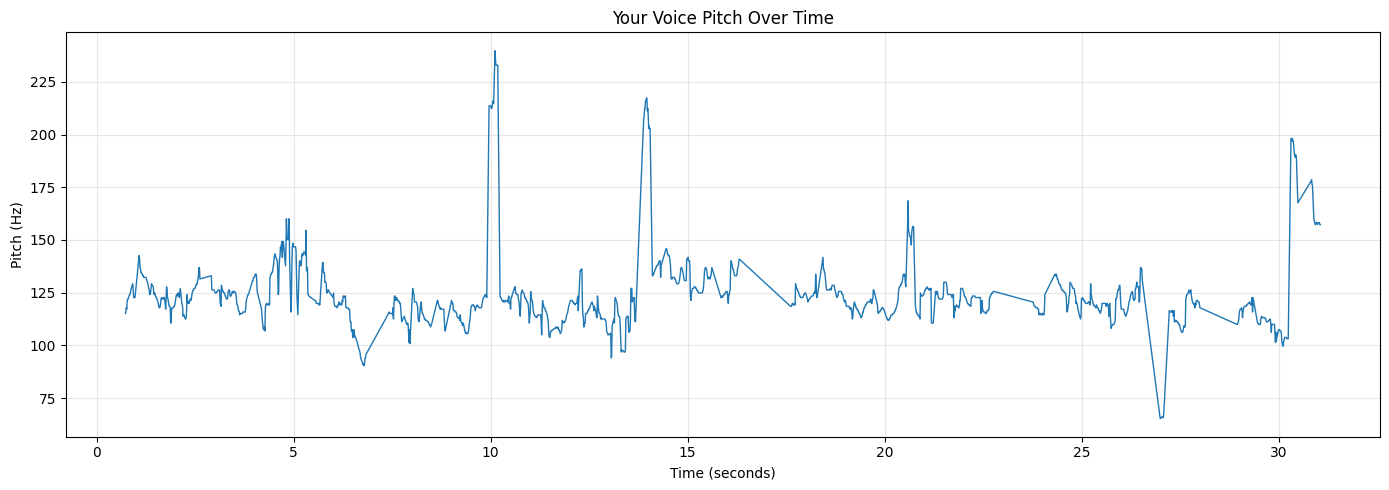

Mean pitch: 123.5 Hz
Minimum detected pitch: 65.4 Hz
Maximum detected pitch: 239.8 Hz
Pitch variation (standard deviation): 17.8 Hz


In [ ]:

# import librosa
# import numpy as np
# import matplotlib.pyplot as plt

# # Load recorded speech
# y, sr = librosa.load("speech.wav", sr=22050)

# # Estimate fundamental frequency (F0)
# f0, voiced_flag, voiced_probs = librosa.pyin(
#     y,
#     fmin=65,
#     fmax=500,
#     sr=sr,
#     frame_length=2048,
#     hop_length=256
# )

# times = librosa.times_like(f0, sr=sr, hop_length=256)

# # Ignore frames where pitch could not be reliably estimated
# valid = np.isfinite(f0)

# plt.figure(figsize=(14, 5))
# plt.plot(times[valid], f0[valid], linewidth=1)
# plt.xlabel("Time (seconds)")
# plt.ylabel("Pitch (Hz)")
# plt.title("Your Voice Pitch Over Time")
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

# if valid.any():
#     print(f"Mean pitch: {np.mean(f0[valid]):.1f} Hz")
#     print(f"Minimum detected pitch: {np.min(f0[valid]):.1f} Hz")
#     print(f"Maximum detected pitch: {np.max(f0[valid]):.1f} Hz")
#     print(f"Pitch variation (standard deviation): {np.std(f0[valid]):.1f} Hz")
# else:
#     print("No reliable pitch detected. Try a clearer recording.")

In [ ]:

# import whisper
# import torch

# model = whisper.load_model("small")

# result = model.transcribe(
#     "my_speech.webm",
#     language="en",  # Change to "hi", "mr", etc.
#     word_timestamps=True,
#     fp16=torch.cuda.is_available(),
#     condition_on_previous_text=False
# )

# transcript = result["text"].strip()

# print("TRANSCRIPT:")
# print(transcript)

# print("\nWORD-LEVEL TIMESTAMPS:")

# word_data = []

# for segment in result["segments"]:
#     for word in segment.get("words", []):
#         item = {
#             "word": word["word"].strip(),
#             "start": round(word["start"], 2),
#             "end": round(word["end"], 2)
#         }
#         word_data.append(item)
#         print(
#             f'{item["start"]:7.2f}s - '
#             f'{item["end"]:7.2f}s  {item["word"]}'
#         )

TRANSCRIPT:
Today's main topic is My brothers and sisters, sing a song and sit down Tie your chair's seat belt Tie the chair's seat belt Gavan is getting a little laggy For today, that's enough We are also from Mayur We are also from Mayur like you But hopefully, the world is ours Bye bye Sky guys today is good morning

WORD-LEVEL TIMESTAMPS:
   0.00s -    1.22s  Today's
   1.22s -    1.60s  main
   1.60s -    1.92s  topic
   1.92s -    2.32s  is
   2.32s -    3.00s  My
   3.00s -    3.38s  brothers
   3.38s -    3.56s  and
   3.56s -    3.88s  sisters,
   4.14s -    4.38s  sing
   4.38s -    5.00s  a
   5.00s -    5.00s  song
   5.52s -    6.14s  and
   6.14s -    6.42s  sit
   6.42s -    7.32s  down
   7.32s -    7.50s  Tie
   7.50s -    7.66s  your
   7.66s -    8.30s  chair's
   8.30s -    8.78s  seat
   8.78s -    9.28s  belt
   9.74s -   10.18s  Tie
  10.18s -   10.26s  the
  10.26s -   10.90s  chair's
  10.90s -   11.24s  seat
  11.24s -   11.66s  belt
  12.14s -   12.58s  Gavan

In [ ]:

# import pandas as pd

# df = pd.DataFrame(word_data)
# display(df)

# # Save results so your React website can use them
# df.to_csv("word_timestamps.csv", index=False)

# print("Saved: word_timestamps.csv")

,word,start,end
0,Today's,0.00,1.22
1,main,1.22,1.60
2,topic,1.60,1.92
3,is,1.92,2.32
4,My,2.32,3.00
5,brothers,3.00,3.38
6,and,3.38,3.56
7,"sisters,",3.56,3.88
8,sing,4.14,4.38
9,a,4.38,5.00


Saved: word_timestamps.csv


In [ ]:

# # ============================================================
# # AI PUBLIC SPEAKING ANALYZER - ALL-IN-ONE CELL
# # Transcript + Filler Words + Speaking Stats + Word Timestamps
# # + Long Pause Detection
# # ============================================================

# import whisper
# import torch
# import re
# from collections import Counter

# # -------------------- SETTINGS --------------------
# AUDIO_FILE = "my_speech.webm"
# LANGUAGE = "en"       # Examples: "en", "hi", "mr", "ta", "te", "kn"
# MODEL_NAME = "small"
# PAUSE_THRESHOLD = 2.0  # Seconds

# # -------------------- LOAD MODEL --------------------
# print("Loading Whisper model...")
# model = whisper.load_model(MODEL_NAME)

# # -------------------- TRANSCRIBE ONCE --------------------
# verbatim_prompt = (
#     "Transcribe this speech verbatim. Preserve hesitations, filler words, "
#     "repetitions, incomplete phrases, and informal speech. Do not clean up "
#     "or summarize. Listen for um, umm, uh, uhh, erm, hmm, like, you know, "
#     "and I mean."
# )

# print("Transcribing audio and finding word timestamps...")

# result = model.transcribe(
#     AUDIO_FILE,
#     language=LANGUAGE,
#     task="transcribe",
#     word_timestamps=True,
#     fp16=torch.cuda.is_available(),
#     initial_prompt=verbatim_prompt,
#     condition_on_previous_text=False,
#     temperature=0
# )

# transcript = result["text"].strip()

# # -------------------- TRANSCRIPT --------------------
# print("\n" + "=" * 55)
# print("VERBATIM TRANSCRIPT")
# print("=" * 55)
# print(transcript)

# # -------------------- WORD DATA --------------------
# word_data = []

# for segment in result["segments"]:
#     for word in segment.get("words", []):
#         word_data.append({
#             "word": word["word"].strip(),
#             "start": float(word["start"]),
#             "end": float(word["end"])
#         })

# # -------------------- FILLER WORD ANALYSIS --------------------
# text = transcript.lower()

# filler_patterns = {
#     "um": r"\bum+\b",
#     "uh": r"\buh+\b",
#     "erm": r"\berm+\b",
#     "hmm": r"\bhm+\b",
#     "you know": r"\byou\s+know\b",
#     "I mean": r"\bi\s+mean\b",
#     "basically": r"\bbasically\b",
#     "actually": r"\bactually\b",
#     "literally": r"\bliterally\b",
# }

# filler_counts = {
#     name: len(re.findall(pattern, text))
#     for name, pattern in filler_patterns.items()
# }

# # "Like" is a candidate because it can also be a normal word.
# like_candidates = len(re.findall(r"\blike\b", text))

# total_fillers = sum(filler_counts.values())
# total_words = len(re.findall(r"\b[\w']+\b", text))

# filler_percentage = (
#     total_fillers / total_words * 100 if total_words else 0
# )

# # -------------------- SPEAKING STATISTICS --------------------
# # Prefer the actual recording duration from your recording cell.
# # If duration_seconds is unavailable, use the last word timestamp.
# try:
#     duration = float(duration_seconds)
# except (NameError, TypeError, ValueError):
#     duration = word_data[-1]["end"] if word_data else 0.0

# duration_minutes = duration / 60
# wpm = total_words / duration_minutes if duration_minutes > 0 else 0

# sentences = [
#     s for s in re.split(r'[.!?]+', transcript.strip()) if s.strip()
# ]
# sentence_count = len(sentences)
# average_sentence_length = (
#     total_words / sentence_count if sentence_count else 0
# )

# # -------------------- WORD TIMESTAMPS --------------------
# print("\n" + "=" * 55)
# print("WORD-LEVEL TIMESTAMPS")
# print("=" * 55)

# for item in word_data:
#     print(
#         f'{item["start"]:7.2f}s - {item["end"]:7.2f}s  '
#         f'{item["word"]}'
#     )

# # -------------------- LONG PAUSE DETECTION --------------------
# pauses = []

# for i in range(1, len(word_data)):
#     previous_word = word_data[i - 1]
#     current_word = word_data[i]

#     pause_duration = current_word["start"] - previous_word["end"]

#     if pause_duration >= PAUSE_THRESHOLD:
#         pauses.append({
#             "after_word": previous_word["word"],
#             "before_word": current_word["word"],
#             "pause_start": previous_word["end"],
#             "pause_end": current_word["start"],
#             "duration": pause_duration
#         })

# # -------------------- FINAL REPORT --------------------
# print("\n" + "=" * 55)
# print("SPEAKING REPORT")
# print("=" * 55)

# print(f"Duration: {duration:.2f} seconds")
# print(f"Total transcript words: {total_words}")
# print(f"Speaking speed: {wpm:.2f} words per minute")
# print(f"Sentence count: {sentence_count}")
# print(f"Average sentence length: {average_sentence_length:.2f} words")

# print("\nFILLER WORD BREAKDOWN")
# for word, count in filler_counts.items():
#     print(f"{word}: {count}")

# print(f"Total detected fillers: {total_fillers}")
# print(f"'Like' occurrences to review: {like_candidates}")
# print(f"Filler percentage: {filler_percentage:.2f}%")

# print("\nLONG PAUSES (>= {:.1f} seconds)".format(PAUSE_THRESHOLD))

# if pauses:
#     for number, pause in enumerate(pauses, start=1):
#         print(f"\nPause #{number}")
#         print(f'After word: {pause["after_word"]}')
#         print(f'Before word: {pause["before_word"]}')
#         print(f'Start: {pause["pause_start"]:.2f} seconds')
#         print(f'End: {pause["pause_end"]:.2f} seconds')
#         print(f'Duration: {pause["duration"]:.2f} seconds')
# else:
#     print("No long pauses detected.")

# print(f"\nTotal long pauses: {len(pauses)}")
# print(
#     "Total long-pause time: "
#     f'{sum(p["duration"] for p in pauses):.2f} seconds'
# )

# print("\nAnalysis complete!")

Loading Whisper model...


100%|███████████████████████████████████████| 461M/461M [00:10<00:00, 48.4MiB/s]


Transcribing audio and finding word timestamps...

VERBATIM TRANSCRIPT
Hi guys, I am from India. I am not from Pakistan. Okay. Umm, nothing. Stop.

WORD-LEVEL TIMESTAMPS
   0.00s -    1.36s  Hi
   1.36s -    1.70s  guys,
   1.84s -    2.00s  I
   2.00s -    2.08s  am
   2.08s -    2.28s  from
   2.28s -    2.60s  India.
   2.86s -    2.96s  I
   2.96s -    3.06s  am
   3.06s -    3.22s  not
   3.22s -    3.42s  from
   3.42s -    3.86s  Pakistan.
   7.48s -    8.24s  Okay.
  11.80s -   12.56s  Umm,
  14.54s -   14.96s  nothing.
  18.10s -   18.86s  Stop.

SPEAKING REPORT
Duration: 23.07 seconds
Total transcript words: 15
Speaking speed: 39.02 words per minute
Sentence count: 5
Average sentence length: 3.00 words

FILLER WORD BREAKDOWN
um: 1
uh: 0
erm: 0
hmm: 0
you know: 0
I mean: 0
basically: 0
actually: 0
literally: 0
Total detected fillers: 1
'Like' occurrences to review: 0
Filler percentage: 6.67%

LONG PAUSES (>= 2.0 seconds)

Pause #1
After word: Pakistan.
Before word: Okay.
Start